# Twitter: from the 1% stream archive to daily counts

This notebook follows the Twitter data through the pipeline (`pipeline/01_extract_twitter.py` to `pipeline/05_daily_counts.py`), with the counts of the stored outputs and hand-made examples of every rule. The notebook runs on the outputs in `data/pipeline/` and reads only stats files and aggregate counts. Every example text is hand-made; no real post, post id or account id is shown. Run it from `code/notebooks/` after the pipeline has run.

In [1]:
%matplotlib inline
import importlib
import json
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

CODE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(CODE))
from pipeline import config, rules as R  # noqa: E402

OUT = config.OUT_DIR          # data/pipeline/ (never printed: it is a local path)
con = duckdb.connect()
con.execute("SET TimeZone='UTC'")
R.register_udfs(con)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 160)


def stats(*parts):
    """A stats file of the pipeline, by its path under data/pipeline/."""
    return json.loads(OUT.joinpath(*parts).read_text())


def src(*parts):
    """SQL source for Parquet files under data/pipeline/ (glob patterns allowed)."""
    return f"read_parquet('{OUT.joinpath(*parts)}', hive_partitioning = false)"


def q(sql):
    return con.execute(sql).df()


def annotate(texts, own=None):
    """Hand-made texts through the computed columns of step 2 (rules.annotate_sql).
    Evidence reads `text` (the full text), structure reads `own` (the author's own words)."""
    own = own or texts
    rows = ", ".join(f"({i}, {R.dq(t)}, {R.dq(o)})" for i, (t, o) in enumerate(zip(texts, own)))
    con.execute(f"CREATE OR REPLACE TEMP TABLE hand_made AS SELECT * FROM (VALUES {rows}) v(i, text, own)")
    con.execute("CREATE OR REPLACE TEMP TABLE annotated AS " +
                R.annotate_sql("SELECT i, text, own FROM hand_made", "text", "own") + " ORDER BY i")
    return q("SELECT * FROM annotated ORDER BY i")


def gates(extra=""):
    """The coin gate (rules.coin_gate) and the market rule on the last annotated examples."""
    coins = ", ".join(f"{R.coin_gate(c)} AS {c.lower()}" for c in R.COINS)
    any_coin = " OR ".join(R.coin_gate(c) for c in R.COINS)
    return q(f"SELECT text, {coins}, {R.market_rule(any_coin)} AS market{extra} FROM annotated ORDER BY i")


def daily_summary(platform):
    """Posts per UTC day after the bot filter, per series (step 5)."""
    d = q(f"""SELECT series, CAST(count(*) AS BIGINT) AS days, CAST(sum(n_posts) AS BIGINT) AS posts,
                     round(avg(n_posts), 1) AS mean_per_day, median(n_posts) AS median_per_day,
                     CAST(min(n_posts) AS BIGINT) AS min_per_day, CAST(max(n_posts) AS BIGINT) AS max_per_day,
                     CAST(count_if(n_posts = 0) AS BIGINT) AS days_without_posts
              FROM {src('panel', 'daily_counts.parquet')} WHERE platform = '{platform}' GROUP BY 1""")
    order = ["BTC", "ETH", "BNB", "XRP", "DOGE", "MARKET", "CRYPTO_SET"]
    d["k"] = [order.index(s) if s in order else 99 for s in d.series]
    return d.sort_values(["k", "series"]).drop(columns="k").set_index("series")


def weekly_plot(platform, title):
    # Twitter: a day without any capture is missing, not a day without posts (its count is 0 in the table;
    # how the attention variable treats such days is decision D14). Those days are left out of the weekly
    # mean, so a week without any capture shows as a gap in the line.
    keep = "TRUE" if platform != "twitter" else (
        f"day IN (SELECT utc_day FROM {src('twitter', 'units', 'twitter_coverage_utc.parquet')} WHERE minutes_utc > 0)")
    w = q(f"""SELECT series, date_trunc('week', day) AS week, avg(n_posts) FILTER (WHERE {keep}) AS posts_per_day
              FROM {src('panel', 'daily_counts.parquet')}
              WHERE platform = '{platform}' AND series IN ('BTC', 'ETH', 'BNB', 'XRP', 'DOGE', 'MARKET')
              GROUP BY 1, 2 ORDER BY 2""")
    fig, ax = plt.subplots(figsize=(9, 4))
    for s in ["BTC", "ETH", "BNB", "XRP", "DOGE", "MARKET"]:
        x = w[w.series == s]
        ax.plot(x.week, x.posts_per_day, label=s, linewidth=1)
    ax.set_yscale("log")
    ax.set_ylabel("posts per day (weekly mean, log scale)")
    ax.set_title(title)
    ax.legend(ncol=6, fontsize=8, frameon=False)
    fig.tight_layout()
    return fig


## Step 1: extract (`01_extract_twitter.py`)

The Internet Archive's Twitter Stream Grab (the 1% sample stream, one archive per day, one file per minute) was converted once, on VMs, to one Parquet file per day and table (tweets, retweets), keeping English and undetermined posts ("Stage A", on Google Drive). Two JSON formats need two parsers: API v1.1 up to 2022-11-22 and API v2 from 2022-12-13; the mirror has no archive in between. Until 2021-08-22 an archive day is a US Mountain-time day, so the capture of a **UTC** day is computed from the per-minute ledgers (step 2, part 3):

In [2]:
cov = q(f"SELECT * FROM {src('twitter', 'units', 'twitter_coverage_utc.parquet')}")
classes = pd.cut(cov.coverage_pct_utc, [-0.1, 0, 50, 95, 100], labels=["no capture", "under 50%", "50-95%", "95% or more"])
print(f"{len(cov):,} UTC days; captured minutes per day: median {cov.minutes_utc.median():.0f} of 1,440")
classes.value_counts().reindex(["95% or more", "50-95%", "under 50%", "no capture"]).rename("UTC days").to_frame()

1,280 UTC days; captured minutes per day: median 1411 of 1,440


,UTC days
coverage_pct_utc,
95% or more,1117
50-95%,62
under 50%,25
no capture,76


In [3]:
days = sorted(p.name.split("=")[1] for p in OUT.joinpath("twitter", "coarse").glob("date=*"))
tot = {"tweets": [0, 0], "retweets": [0, 0]}
for d in days:
    c = stats("twitter", "coarse", f"date={d}", "_stats.json")["counts"]
    for t in tot:
        if t in c:
            tot[t][0] += c[t]["rows_in"]
            tot[t][1] += c[t]["rows_out"]
pd.DataFrame(tot, index=["in Stage A", "kept by the coarse pass"]).T.assign(
    pct_kept=lambda d: (100 * d["kept by the coarse pass"] / d["in Stage A"]).round(2)).rename_axis(f"{len(days):,} day files")

,in Stage A,kept by the coarse pass,pct_kept
"1,189 day files",,,
tweets,867129500,13182273,1.52
retweets,962428772,17022719,1.77


## Step 2: coarse pass, one row per tweet, coverage (`02_filter_twitter.py`)

**Coarse pass.** A tweet is kept if its text plus its quoted text matches the inclusion pattern; a retweet if the original's text does. Screen names are turned into a flag ("bot" in the name) and never written. A tweet's writing time can be read from its id (Twitter ids carry their creation time); a made-up id:

In [4]:
EPOCH = 1288834974657                        # Twitter's id epoch, in ms (step 2, SNOWFLAKE_EPOCH_MS)
ms = int(pd.Timestamp("2021-05-10 12:00:00", tz="UTC").timestamp() * 1000)
made_up_id = (ms - EPOCH) << 22                # any id made at that millisecond
q(f"SELECT {made_up_id} AS made_up_id, epoch_ms(CAST(({made_up_id} >> 22) + {EPOCH} AS BIGINT)) AS written_at_utc")

,made_up_id,written_at_utc
0,1391724699448246272,2021-05-10 12:00:00


**One row per tweet.** The stream captures a tweet directly, inside retweets, or both, often several times. Captures are merged by id, never by text. A tweet's text is its longest captured copy (a retweet copy wins over a direct capture only when strictly longer); among equally long copies the earliest captured wins, then the first in sort order (decided 28 Sep 2026: 23 tweets had such a tie, 11 of them changed text). A hand-made example with three copies of one tweet:

In [5]:
q("""SELECT unit, arg_min(text, (-length(text), ts, text)) AS chosen_text
     FROM (VALUES (1, 'doge news', TIMESTAMP '2021-05-10 11:00'),
                  (1, 'doge news today B', TIMESTAMP '2021-05-10 12:00'),
                  (1, 'doge news today A', TIMESTAMP '2021-05-10 12:05')) v(unit, text, ts)
     GROUP BY unit""")

,unit,chosen_text
0,1,doge news today B


Tweets known only through retweets (`retweet_only`) are dated at their first sampled retweet; their writing time is kept as `authored_at`. The units:

In [6]:
u = stats("twitter", "units", "units.parquet.stats.json")["counts"]
print(f"{u['units']:,} tweets; {u['retweet_events']:,} retweet events (from {u['retweet_rows']:,} retweet rows); "
      f"{u['text_variants']:,} other captured texts; text taken from a retweet copy: {u['text_from_retweet']:,}; "
      f"retweet-only tweets written before the window: {u['authored_before_window']:,}")
pd.Series(u["roles"], name="tweets").rename_axis("role").to_frame()

19,366,142 tweets; 17,005,614 retweet events (from 17,022,719 retweet rows); 17,811 other captured texts; text taken from a retweet copy: 802; retweet-only tweets written before the window: 22,523


,tweets
role,
original,3486113
quote,2618140
reply,7065605
retweet_only,6196284


## Step 3: bot filter (`03_bot_filter.py`)

The same rules as on the other platforms, each on all tweets with its own flag, each using only data up to the tweet's UTC day.

| Rule | Criterion | Source |
|---|---|---|
| keyword | at least 2 of: give-away words; pump with join/register; > 5 hashtags; > 5 crypto tickers; "bot" in the name | Kraaijeveld & De Smedt (2020), Electronic Markets (2025) |
| campaign | a fingerprint posted by >= 20 accounts on one UTC day forms a group; a member account is a bot that day if >= 60% of its window carry fingerprints found in the windows of >= 3 of the group's accounts | Chen & Subramanian (2018) |
| template | more than half of the pairs in an account's window are near-copies (difflib ratio > 0.7) | Electronic Markets (2025) |
| invite | Telegram/Discord invite link: flag only, never in `bot_any` | Nizzoli et al. (2020) |

In [7]:
f = stats("twitter", "bot", "post_flags.parquet.stats.json")["counts"]
rules = pd.DataFrame({"posts flagged": f["flags"], "flagged by this rule only": f.get("flag_only_this_rule", {})}).astype("Int64")
rules.index.name = "rule"
print(f"{f['posts']:,} posts; campaign groups: {f['campaign']['groups']:,}; "
      f"template bot account-days: {f['template']['bot_account_days']:,} of {f['template']['account_days']:,}")
rules

19,366,142 posts; campaign groups: 11,588; template bot account-days: 749,902 of 15,869,876


,posts flagged,flagged by this rule only
rule,,
bot_keyword,57155,45314
bot_campaign,744630,619970
bot_template,1576676,1446398
invite_link,1547,<NA>
bot_any,2244623,<NA>


## Step 4: series (`04_series_twitter.py`)

The coin gate and the market rule of StockTwits, without symbols, on the tweet's text plus the quoted text. On three hand-made texts (the first stands for a quote tweet: its own words and the quoted text together, as the gate reads them):

In [8]:
annotate(["what do you think? ethereum is breaking out", "doge to the moon", "bitcoin and crypto everywhere"])
gates()

,text,btc,eth,bnb,xrp,doge,market
0,what do you think? ethereum is breaking out,False,True,False,False,False,False
1,doge to the moon,False,False,False,False,False,False
2,bitcoin and crypto everywhere,True,False,False,False,False,False


In [9]:
a = stats("twitter", "panel", "assignment.parquet.stats.json")["counts"]
fc, after = a["flag_counts"], a["series_after_bot_pass"]
series = pd.DataFrame({"posts in the series": {s: fc[f"in_{s}"] for s in after},
                       "after the bot filter": after})
series["removed by the bot filter"] = series["posts in the series"] - series["after the bot filter"]
series.index = [s.upper() for s in series.index]
series
q(f"""SELECT CAST(count_if(in_btc AND NOT bot_any AND NOT authored) AS BIGINT) AS btc_retweet_only,
             CAST(count_if(in_eth AND NOT bot_any AND NOT authored) AS BIGINT) AS eth_retweet_only,
             CAST(count_if(in_market AND NOT bot_any AND NOT authored) AS BIGINT) AS market_retweet_only
      FROM {src('twitter', 'panel', 'assignment.parquet')}""")

,btc_retweet_only,eth_retweet_only,market_retweet_only
0,808775,665061,1609275


## Step 5: daily counts (`05_daily_counts.py`)

Twitter also has `<SERIES>_RETWEET_EVENTS`: every retweet event on its own day (robustness A12).

In [10]:
daily_summary("twitter")

,days,posts,mean_per_day,median_per_day,min_per_day,max_per_day,days_without_posts
series,,,,,,,
BTC,1280,2121642,1657.5,1718.0,0,6286,76
ETH,1280,1411220,1102.5,715.5,0,7766,76
BNB,1280,613949,479.6,319.0,0,1599,76
XRP,1280,372654,291.1,241.0,0,2168,76
DOGE,1280,486452,380.0,259.0,0,9617,76
MARKET,1280,5695446,4449.6,3246.0,0,13195,76
CRYPTO_SET,1280,9744883,7613.2,6686.5,0,25124,76
BNB_RETWEET_EVENTS,1280,937019,732.0,505.5,0,2717,77
BTC_RETWEET_EVENTS,1280,2086295,1629.9,1627.0,0,9811,76


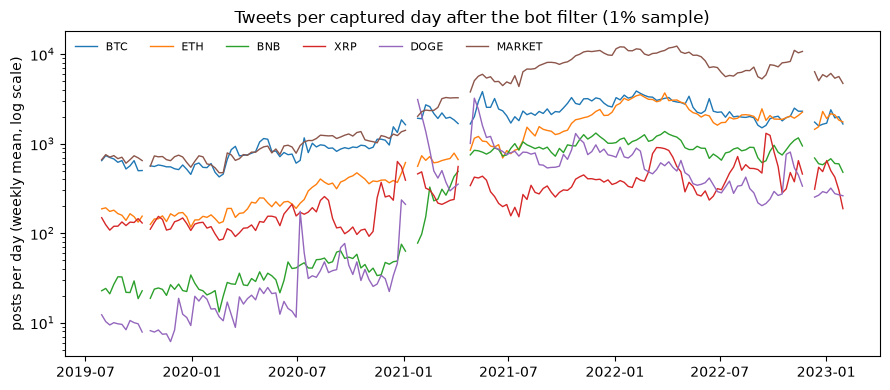

In [11]:
fig = weekly_plot("twitter", "Tweets per captured day after the bot filter (1% sample)")